In [1]:
import sys
import os

# Agregar el directorio padre al sys.path
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import os
from sklearn.preprocessing import StandardScaler
import sqlite3

import json

import mlp.promok_functions as pk
import mlp.promok_models_config as pkconfig
from mlp.dataframe_tracker import *

import cashia_core.data_channel.promok_datapipe_func as pkdp
import cashia_core.data_channel.pm_datapipeline as pmdp


from datetime import datetime

In [2]:
import sys, pandas as pd, numpy as np, sklearn
print(sys.executable)
print("pandas", pd.__version__)
print("numpy", np.__version__)
print("sklearn", sklearn.__version__)

c:\Users\juan_\.conda\envs\cashia_env\python.exe
pandas 1.5.3
numpy 1.26.0
sklearn 1.2.2


In [3]:
date_and_time = datetime.now()
# Convierte la fecha y hora en una cadena con el formato deseado
str_date_and_time = date_and_time.strftime("%Y:%m:%d:%H:%M")

print(str_date_and_time)

all_stats = pk.ModelsStats()
all_stats.base_stats

2026:11:13:19:23


dict_values(['13/11/2026 19:23:10', 'Undefined', 'Undefined', 'Undefined', 'Undefined', 'Unknown', 'Unknown', -1, -1, -1, -1.0, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, None, -1, 'Unknown', 'Unknown', 'None', 'None', 'None'])

## 1 Lectura de datos de configuración

### 1.1 Datos categóricos

In [4]:
print('Configuration file: ', pkconfig.configuration_file_name)
all_features = pd.read_excel("./config/"+pkconfig.configuration_file_name, index_col=0)
features = all_features[all_features[pkconfig.conf_column] == 'Sí']

features_to_use = set(features['Característica'].values)
features_to_use

Configuration file:  CashIA_ConfFile.xlsx


c:\Users\juan_\.conda\envs\cashia_env\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


{'CP',
 'CP Aval',
 'CP_Aval_Latitud',
 'CP_Aval_Longitud',
 'CP_Latitud',
 'CP_Longitud',
 'Deficit',
 'Dependientes',
 'Egresos',
 'Frecuencia_Ant',
 'Genero',
 'Incobrable',
 'IngresoPercapita',
 'Ingresos',
 'Mes inicial',
 'Monto',
 'Odds',
 'Score CC',
 'TipoZona',
 'Unidad'}

In [5]:
categorical_features = set(features[(features['Tipo de dato'] == 'Categórico') & (features['Tipo de variable'] == 'Predictor')]['Característica'].values)
categorical_features

{'CP', 'Genero', 'TipoZona', 'Unidad'}

### 1.2 Datos cuantitativos

In [6]:
quantitative_features = set(features[(features['Tipo de dato'] == 'Cuantitativo') & (features['Tipo de variable'] == 'Predictor')]['Característica'].values)
quantitative_features

{'CP Aval',
 'CP_Aval_Latitud',
 'CP_Aval_Longitud',
 'CP_Latitud',
 'CP_Longitud',
 'Deficit',
 'Dependientes',
 'Egresos',
 'Frecuencia_Ant',
 'IngresoPercapita',
 'Ingresos',
 'Mes inicial',
 'Monto',
 'Odds',
 'Score CC'}

In [7]:
monetary_features = features[features['Monetario'] == 1]['Característica']

### 1.3 Registro de las características de los datos en las estadísticas

In [8]:
categorical_list = list(categorical_features)
categorical_list.sort()

quantitative_list = list(quantitative_features)
quantitative_list.sort()

all_stats.base_stats.fields["Model"] = pkconfig.conf_column
all_stats.base_stats.fields["Features"] = json.dumps({"Categorical":categorical_list,"Quantitative":quantitative_list})
all_stats.base_stats.fields["Notes"] = pkconfig.notes
all_stats.base_stats.fields["SourceFile"] = pkconfig.data_file_name

In [9]:
all_stats.base_stats

dict_values(['13/11/2026 19:23:10', 'Undefined', 'Undefined', 'Undefined', 'Undefined', 'Unknown', 'Unknown', -1, -1, -1, -1.0, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, None, -1, '{"Categorical": ["CP", "Genero", "TipoZona", "Unidad"], "Quantitative": ["CP Aval", "CP_Aval_Latitud", "CP_Aval_Longitud", "CP_Latitud", "CP_Longitud", "Deficit", "Dependientes", "Egresos", "Frecuencia_Ant", "IngresoPercapita", "Ingresos", "Mes inicial", "Monto", "Odds", "Score CC"]}', 'Unknown', "zip_digits = 4  Usando: standardizationSin remplazar campos vacios por 'Unknown'", 'Data Set Cashia EntrenamientoRNV_CCProcessed.csv', 'RNV_CC'])

## 2 Lectura de los datos de entrenamiento

In [10]:
print('Data file: ', pkconfig.data_file_name)
data = pd.read_csv("./data/"+pkconfig.data_file_name, parse_dates=['Fecha Inicial'], index_col=0, dayfirst=True)
# Convertir a entero el índice
data.index = data.index.astype(int)
# Ordenar el DataFrame por el índice de menor a mayor
data = data.sort_index()
# pkdp.print_sizes(data)
data_tracker = DataFrameEvolutionTracker(data)
data_tracker.to_dataframe()

Data file:  Data Set Cashia EntrenamientoRNV_CCProcessed.csv


,Step,Rows,Columns,Column Names
0,Initialization,1656,21,"[Fecha Inicial, Monto, Genero, Dependientes, C..."


### 2.1 Borramos la columna de 'Score' si está presente ya que es una variable 'Target' usada en otro contexto.

In [11]:
if 'Score' in data.columns:
    data = data.drop(columns=['Score'])

In [12]:
data.head()

,Fecha Inicial,Monto,Genero,Dependientes,CP,CP Aval,Ingresos,Egresos,Score CC,Unidad,...,Incobrable,Deficit,IngresoPercapita,TipoZona,CP_Latitud,CP_Longitud,CP_Aval_Latitud,CP_Aval_Longitud,Odds,Mes inicial
index,,,,,,,,,,,,,,,,,,,,,
61612,2023-03-28,3000,Femenino,0,72310,72000,1000,1000,545,Puebla Norte,...,0,0,1000.0,Urbano,19.069975,-98.166425,19.047900,-98.190700,2.75,3
67298,2023-01-09,6000,Femenino,2,94106,94100,18000,15000,456,Cordoba,...,0,3000,6000.0,Urbano,19.267300,-96.965050,19.397700,-96.990400,1.50,1
67811,2023-01-11,5000,Femenino,1,94140,94140,8000,4000,662,Cordoba,...,0,4000,4000.0,Urbano,19.048355,-97.095255,19.048355,-97.095255,6.10,1
68492,2023-01-16,5500,Femenino,0,74400,72000,8500,0,565,Puebla Poniente,...,1,8500,8500.0,Semiurbano,18.602000,-98.466600,19.047900,-98.190700,3.20,1
69057,2023-01-20,3000,Femenino,1,90640,90640,8500,3000,667,Puebla Norte,...,0,5500,4250.0,Urbano,19.346720,-98.135020,19.346720,-98.135020,8.30,1


### 2.2 solo tomamos los datos hasta la fecha indicada

In [13]:
print(data.shape)
data = data[(data['Fecha Inicial'] <= pkconfig.max_date) & (data['Fecha Inicial'] >= pkconfig.min_date)]
pkdp.print_sizes(data)
data_tracker.register_step("Filtered by date range", data)
data_tracker.to_dataframe()

(1656, 21)
Rows: 1656
Columns: 21
Max index: 222983


,Step,Rows,Columns,Column Names
0,Initialization,1656,21,"[Fecha Inicial, Monto, Genero, Dependientes, C..."
1,Filtered by date range,1656,21,"[Fecha Inicial, Monto, Genero, Dependientes, C..."


### 2.3 Registramos datos para las estadísticas

In [14]:
all_stats.base_stats.fields["Size"] = len(data)

## 4 Simplificación del CP a n cifras

In [15]:
if pkconfig.zip_digits <= 4:
    print("Simplificando CP")
    if 'CP' in features_to_use:
        # Guardamos el conjunto de CP para almacenarlos posteriormente en 
        # el campo data_parameters de un modelo
        training_cps = data[['CP']]
        training_cps = training_cps.drop_duplicates().reset_index(drop=True)
        
        pkdp.transform_CP(data,'CP', pkconfig.zip_digits)
        
    if 'CP Aval' in features_to_use:
        # Guardamos el conjunto de CP Aval para almacenarlos posteriormente en 
        # el campo data_parameters de un modelo
        training_cps_aval = data[['CP Aval']]
        training_cps_aval = training_cps_aval.drop_duplicates().reset_index(drop=True)
        training_cps_aval = training_cps_aval.rename(columns={'CP Aval':'CP'})
        
        pkdp.transform_CP(data,'CP Aval', pkconfig.zip_digits)

Simplificando CP


In [16]:
data[monetary_features].head()

,Monto,Ingresos,Egresos,IngresoPercapita
index,,,,
61612,3000,1000,1000,1000.0
67298,6000,18000,15000,6000.0
67811,5000,8000,4000,4000.0
68492,5500,8500,0,8500.0
69057,3000,8500,3000,4250.0


In [17]:
converter = pmdp.CurrentValueConverter(pkconfig.get_mlp_resource_key("inflation_table"))

In [18]:
for feature in monetary_features:
    data = converter.to_current_value(data, 'Fecha Inicial', feature)

In [19]:
data[monetary_features].head()

,Monto,Ingresos,Egresos,IngresoPercapita
index,,,,
61612,3400,1133,1133,1133
67298,6857,20571,17142,6857
67811,5714,9142,4571,4571
68492,6285,9714,0,9714
69057,3428,9714,3428,4857


In [20]:
#data.to_excel("ProcessedData2.xlsx")

In [21]:
converter_500 = pmdp.MultipleAdjuster(500)
data = converter_500.adjust_amount(data, 'Monto')

In [22]:
data[monetary_features].head()

,Monto,Ingresos,Egresos,IngresoPercapita
index,,,,
61612,3500,1133,1133,1133
67298,7000,20571,17142,6857
67811,6000,9142,4571,4571
68492,6500,9714,0,9714
69057,3500,9714,3428,4857


In [23]:
# Monto promedio de los "buenos pagadores"
good_payer = data[data['Incobrable']==0]
good_payer['Monto'].mean()

8019.730941704036

In [24]:
# Monto promedio de los "malos pagadores"
bad_payer = data[data['Incobrable']==1]
bad_payer['Monto'].mean()

7701.478743068392

In [25]:
# Promedio de "Incobrabilidad"
data['Incobrable'].mean()

0.32669082125603865

In [26]:
# Promedio del monto de préstamo
data['Monto'].mean()

7915.760869565217

## 3 Feature engineering directly with sklearn

In [27]:
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OrdinalEncoder

predictors = data.drop(columns=['Incobrable', 'Fecha Inicial'])

target = data['Incobrable']

preprocessor = make_column_transformer(
    (
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=99999999),
        list(categorical_features),
    ),
    (StandardScaler(), list(quantitative_features)),
)


## 6 Run models

In [28]:
train_type = pk.BY_SIZE

In [29]:
if train_type == pk.BY_SIZE:

    
    totals = data["Incobrable"].value_counts()
    
    train_init_date = data.iloc[0]['Fecha Inicial']
    train_end_date = data.iloc[-1]['Fecha Inicial']
    
    data = data.drop('Fecha Inicial', axis=1)
    
    all_stats.base_stats.fields['Paid'] = int(totals[0])
    all_stats.base_stats.fields['Unpaid'] = int(totals[1])
    all_stats.base_stats.fields['AccMin'] = float(max(totals[0],totals[1])/(totals[0]+totals[1])*100)
    
    all_stats.base_stats.fields["TestSize"] = pkconfig.test_size
    models_tester = pk.ModelsTester(data, pkconfig.models_to_test, 
                                    pkconfig.test_size, split=pk.BY_SIZE)
    
elif train_type == pk.BY_INDEX:
    dates = data[['Fecha Inicial']]
    data = data.drop('Fecha Inicial', axis=1)
    
    data_size = data.shape[0]
    train_size = int(data_size/2)
    test_init = int(data_size*4/5)
    test_size = int(data_size/5)

    print("Data size: ", data_size)
    print("Train size: ", train_size)
    print("Test init: ", test_init)
    print("Test size: ", test_size)

    test_data = data.iloc[test_init:test_init+test_size]

    train_init_date = dates.loc[data.index[0],'Fecha Inicial']
    train_end_date = dates.loc[data.index[train_size],'Fecha Inicial']
    test_init_date = dates.loc[data.index[test_init],'Fecha Inicial']
    test_end_date = dates.loc[data.index[test_init+test_size-1],'Fecha Inicial']

    print("Evalueating with:")
    print(f"Train from: {train_init_date} to {train_end_date}")
    print(f"Test from: {test_init_date} to {test_end_date}")

    all_stats.base_stats.fields["TrainInitDate"] = str(train_init_date)
    all_stats.base_stats.fields["TrainEndDate"] = str(train_end_date)
    all_stats.base_stats.fields["TestInitDate"] = str(test_init_date)
    all_stats.base_stats.fields["TestEndDate" ] = str(test_end_date)

    all_stats.base_stats.fields["Size"] = len(test_data)

    totals = test_data["Incobrable"].value_counts()
    all_stats.base_stats.fields['Paid'] = int(totals[0])
    all_stats.base_stats.fields['Unpaid'] = int(totals[1])

    all_stats.base_stats.fields['AccMin'] = float(max(totals[0],totals[1])/(totals[0]+totals[1])*100)
    
    models_tester = pk.ModelsTester(data, pkconfig.models_to_test, pkconfig.test_size,
                                    train_init=0, train_size=train_size, test_init=test_init, 
                                    test_size=test_size, split=pk.BY_INDEX)
    all_stats.base_stats.fields["TestSize"] =  models_tester.x_test.shape[0]/models_tester.data.shape[0]
else:
    train_init_date = data.iloc[0]['Fecha Inicial']
    train_end_date = pd.to_datetime('2022-12-22')

    test_init_date = train_end_date + pd.Timedelta(days=1)
    test_end_date = pd.to_datetime('2023-03-22')
    
    print("Evalueating with:")
    print(f"Train from: {train_init_date} to {train_end_date}")
    print(f"Test from: {test_init_date} to {test_end_date}")
    
  
    all_stats.base_stats.fields["TrainInitDate"] = str(train_init_date)
    all_stats.base_stats.fields["TrainEndDate"] = str(train_end_date)
    all_stats.base_stats.fields["TestInitDate"] = str(test_init_date)
    all_stats.base_stats.fields["TestEndDate" ] = str(test_end_date)

    
    models_tester = pk.ModelsTester(data, pkconfig.models_to_test,  
                                    train_end_date=train_end_date,
                                    test_end_date=test_end_date,
                                    split=pk.BY_DATE)
    
    all_stats.base_stats.fields["TestSize"] = models_tester.x_test.shape[0]/models_tester.data.shape[0]
    all_stats.base_stats.fields["Size"] = models_tester.data.shape[0]

    totals = models_tester.y_test.value_counts()
    all_stats.base_stats.fields['Paid'] = int(totals[0])
    all_stats.base_stats.fields['Unpaid'] = int(totals[1])

    all_stats.base_stats.fields['AccMin'] = float(max(totals[0],totals[1])/(totals[0]+totals[1])*100)

In [30]:
data.shape

(1656, 20)

In [31]:
models_tester.x_train.columns

Index(['Monto', 'Genero', 'Dependientes', 'CP', 'CP Aval', 'Ingresos',
       'Egresos', 'Score CC', 'Unidad', 'Frecuencia_Ant', 'Deficit',
       'IngresoPercapita', 'TipoZona', 'CP_Latitud', 'CP_Longitud',
       'CP_Aval_Latitud', 'CP_Aval_Longitud', 'Odds', 'Mes inicial'],
      dtype='object')

In [32]:
all_columns = list(data.columns)
all_columns.sort()
all_columns

['CP',
 'CP Aval',
 'CP_Aval_Latitud',
 'CP_Aval_Longitud',
 'CP_Latitud',
 'CP_Longitud',
 'Deficit',
 'Dependientes',
 'Egresos',
 'Frecuencia_Ant',
 'Genero',
 'Incobrable',
 'IngresoPercapita',
 'Ingresos',
 'Mes inicial',
 'Monto',
 'Odds',
 'Score CC',
 'TipoZona',
 'Unidad']

### Correr los diferentes modelos (hacer el 'fit' con cada uno de ellos) con los datos de entrenamiento

In [33]:
models_tester.run_all_models(preprocessor)

Running: Random_Forest


### Correr los modelos con los datos de prueba y desplegar las estadísticas

********************* Results for model: Random_Forest : {'criterion': 'gini', 'bootstrap': True, 'random_state': 100} *********************
********************** TEST **********************
********************** TRAIN **********************
**************** Unbral para best accurracy *******************
Best threshold =  0.6


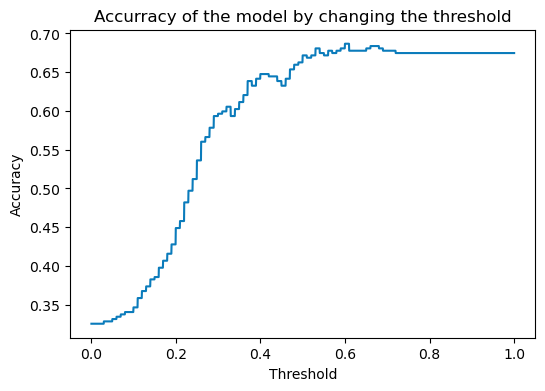

Pagados: 1115 Incobrables: 541
Accuracy mínimo: 67.33091787439614
Tamaño del data set:  1656
Porcentaje de impagados: 32.6691
------Best accurracy threshold Test scores for Random_Forest------
Recall: 8.3333
Precision: 64.2857
F1-Score: 14.7541
Accuracy score: 68.6747
AUC Score: 53.0506
Accurracy Gain:  1.9958
Monetary Gain:  $-187,258
Reference Value:  $-221,744
Improvement:  15.6%
Model rejection rate 4.2%
False negative rate 31.1%


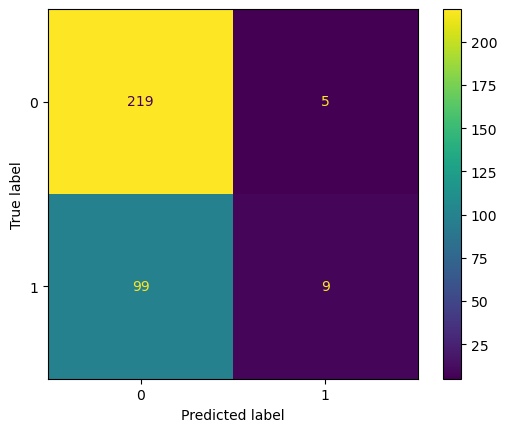

**************** Unbral para best monetary gain Test *******************
Best gain threshold =  0.37


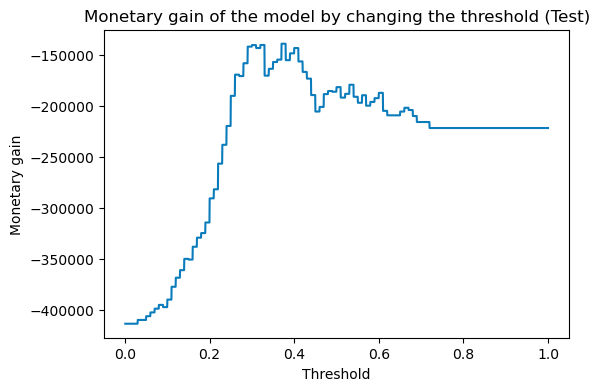

Model configuration:RNV_CC
Pagados: 1115 Incobrables: 541
Accuracy mínimo: 67.33091787439614
Tamaño del data set:  1656
Porcentaje de impagados: 32.6691
------Best monetary gain threshold Test scores for Random_Forest------
Recall: 53.7037
Precision: 45.3125
F1-Score: 49.1525
Accuracy score: 63.8554
AUC Score: 61.2269
Accurracy Gain:  -5.1618
Monetary Gain:  $-139,052
Reference Value:  $-221,744
Improvement:  37.3%
Model rejection rate 38.6%
False negative rate 24.5%


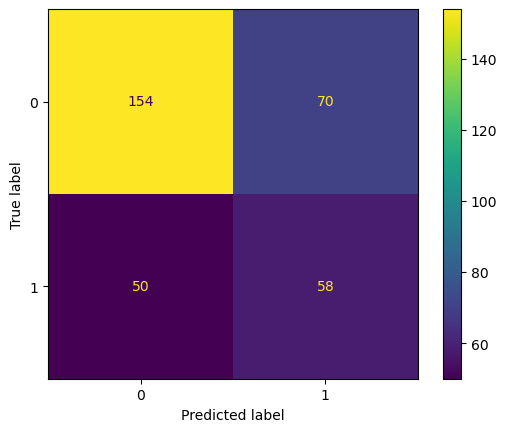

**************** Unbral para best monetary gain Train *******************
Best gain threshold =  0.38 with a monetary gain of 1645677.0


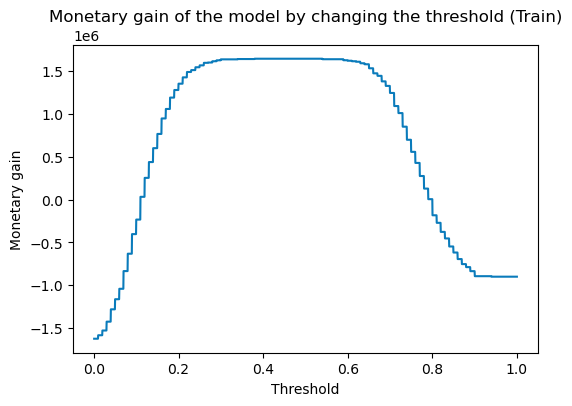

In [34]:
for model in models_tester.models:
    print(f"********************* Results for model: { model.name} : {model.parameters} *********************")
    print("********************** TEST **********************")
    y_pred_test = model.pipeline.predict(models_tester.x_test)
    all_stats.add_and_print_stats(models_tester.y_test, y_pred_test, model.name, model.parameters, "Test")

    print("********************** TRAIN **********************")
    y_pred_train = model.pipeline.predict(models_tester.x_train)
    all_stats.add_and_print_stats(models_tester.y_train, y_pred_train, model.name, model.parameters, "Train")
    
    #if (model.name != "Random Forest") and (model.name != "Ada Boost"):
    if (model.name != "Ada Boost"):
        ### Estadisticas con el mejor umbral para el accurracy y monetary gain

        predictions = model.pipeline.predict_proba(models_tester.x_test)[:,1]
        acceptance_threshold, accurracy_list, best_threshold, best_accurracy, gl, bgt, bg =  \
                                                                        pk.find_best_threshold(predictions, models_tester.y_test)
        model.best_gain_threshold = bgt
        model.best_accurracy_threshold = best_threshold
        
        print("**************** Unbral para best accurracy *******************")
        print("Best threshold = ", best_threshold)
        pk.plot_threshold_evolution(acceptance_threshold, accurracy_list, "Accurracy of the model by changing the threshold",
                                    "Threshold","Accuracy",
                                    f"{pkconfig.conf_column}_{model.name}_accuracy_test.png")
        y_pred_accuracy = np.where(predictions > best_threshold, 1, 0)
        all_stats.add_and_print_stats(models_tester.y_test, y_pred_accuracy, model.name, model.parameters, 
                                      "Best accurracy threshold Test", True,
                                      f"CM_{pkconfig.conf_column}_{model.name}_accuracy_test.png")

        ### Estadísticas de con la mejor ganancia monetária
        print("**************** Unbral para best monetary gain Test *******************")
        print("Best gain threshold = ", bgt)
        pk.plot_threshold_evolution(acceptance_threshold, gl, 
                                    "Monetary gain of the model by changing the threshold (Test)", 
                                    "Threshold", "Monetary gain",
                                    f"{pkconfig.conf_column}_{model.name}_best_gain_test.png")
        y_pred_monetary_test = np.where(predictions > bgt, 1, 0)
        print(f"Model configuration:{pkconfig.conf_column}")
        all_stats.add_and_print_stats(models_tester.y_test, y_pred_monetary_test, model.name, model.parameters, 
                                      "Best monetary gain threshold Test", True,
                                      f"CM_{pkconfig.conf_column}_{model.name}_monetary_test.png")

        ### Estadísticas con la mejor ganancia monetária datos de entrenamiento
        print("**************** Unbral para best monetary gain Train *******************")
        predictions = model.pipeline.predict_proba(models_tester.x_train)[:,1]
        acceptance_threshold, accurracy_list, best_threshold, best_accurracy, gl, bgt, bg = pk.find_best_threshold(predictions, models_tester.y_train)

        print("Best gain threshold = ", bgt, "with a monetary gain of", bg)
        pk.plot_threshold_evolution(acceptance_threshold, gl, "Monetary gain of the model by changing the threshold (Train)",
                                    "Threshold", "Monetary gain",
                                    f"{pkconfig.conf_column}_{model.name}_best_gain_train.png")

        y_pred_monetary_train = np.where(predictions > bgt, 1, 0)
        all_stats.add_and_print_stats(models_tester.y_train, y_pred_monetary_train, model.name, model.parameters,"Best monetary gain threshold Train")
    #model.min_max_stats = min_max_stats
    model.columns = models_tester.x_train.columns
    model.feature_engineering = pkconfig.feature_engineering
    model.features = all_features
    model.conf_column = pkconfig.conf_column
    model.data_parameters['zip_digits'] = pkconfig.zip_digits
    model.data_parameters['Training init date'] = train_init_date
    model.data_parameters['Trainig en date'] = train_end_date
    model.data_parameters['SourceFile'] = pkconfig.source_file_name
    model.data_parameters['Date'] = str_date_and_time
    if 'CP' in features_to_use:
        model.data_parameters['CP'] = training_cps
    if 'CP Aval' in features_to_use:
        model.data_parameters['CP Aval'] = training_cps_aval
    model.save_with_pickle()

In [35]:
for model in models_tester.models:
    print(model)
    print("=====================================")

Model name: Random_Forest
Feature engineering: standardization
Best gain threshold: 0.37



# Write statistics

## Write to data base

In [36]:
con = sqlite3.connect("promocash_stats.db")
cur = con.cursor()
cur.executemany("INSERT INTO stats VALUES(?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)", all_stats.values)
con.commit()

### Leer de la base de datos para escribir las estadísticas en la base de datos

In [37]:
df = pd.read_sql_query("SELECT * FROM stats", con)
df

,Date,TrainInitDate,TrainEndtDate,testInitDate,TestEndDate,Method,Evaluation,Size,Paid,Unpaid,...,ReferenceValue,Improvement,RejectionRate,ConfusionMatrix,False,Fetures,Parameters,Notes,SourceFile,Model
0,24/04/2024 17:36:30,Undefined,Undefined,Undefined,Undefined,Random_Forest_SMOTE,Test,28779,23368,5411,...,2266390.0,0.179125,0.125956,[[4271 403]\n [ 760 322]],0.151063,"{""Categorical"": [""CP"", ""Genero"", ""TipoZona"", ""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Valores Act Rech2NV_AgtProcessed.csv,NV_Agt
1,24/04/2024 17:36:30,Undefined,Undefined,Undefined,Undefined,Random_Forest_SMOTE,Train,28779,23368,5411,...,9055982.0,2.812708,0.188029,[[18694 0]\n [ 0 4329]],0.000000,"{""Categorical"": [""CP"", ""Genero"", ""TipoZona"", ""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Valores Act Rech2NV_AgtProcessed.csv,NV_Agt
2,24/04/2024 17:36:30,Undefined,Undefined,Undefined,Undefined,Random_Forest_SMOTE,Best accurracy threshold Test,28779,23368,5411,...,2266390.0,0.216101,0.028318,[[4625 49]\n [ 968 114]],0.173073,"{""Categorical"": [""CP"", ""Genero"", ""TipoZona"", ""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Valores Act Rech2NV_AgtProcessed.csv,NV_Agt
3,24/04/2024 17:36:30,Undefined,Undefined,Undefined,Undefined,Random_Forest_SMOTE,Best monetary gain threshold Test,28779,23368,5411,...,2266390.0,0.243064,0.066887,[[4495 179]\n [ 876 206]],0.163098,"{""Categorical"": [""CP"", ""Genero"", ""TipoZona"", ""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Valores Act Rech2NV_AgtProcessed.csv,NV_Agt
4,24/04/2024 17:36:30,Undefined,Undefined,Undefined,Undefined,Random_Forest_SMOTE,Best monetary gain threshold Train,28779,23368,5411,...,9055982.0,2.812708,0.188029,[[18694 0]\n [ 0 4329]],0.000000,"{""Categorical"": [""CP"", ""Genero"", ""TipoZona"", ""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Valores Act Rech2NV_AgtProcessed.csv,NV_Agt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
850,13/11/2026 19:23:10,Undefined,Undefined,Undefined,Undefined,Random_Forest,Test,1656,1115,541,...,-221744.0,0.180866,0.123494,[[203 21]\n [ 88 20]],0.302405,"{""Categorical"": [""CP"", ""Genero"", ""TipoZona"", ""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Data Set Cashia EntrenamientoRNV_CCProcessed.csv,RNV_CC
851,13/11/2026 19:23:10,Undefined,Undefined,Undefined,Undefined,Random_Forest,Train,1656,1115,541,...,-902095.0,2.824283,0.327039,[[891 0]\n [ 0 433]],0.000000,"{""Categorical"": [""CP"", ""Genero"", ""TipoZona"", ""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Data Set Cashia EntrenamientoRNV_CCProcessed.csv,RNV_CC
852,13/11/2026 19:23:10,Undefined,Undefined,Undefined,Undefined,Random_Forest,Best accurracy threshold Test,1656,1115,541,...,-221744.0,0.155522,0.042169,[[219 5]\n [ 99 9]],0.311321,"{""Categorical"": [""CP"", ""Genero"", ""TipoZona"", ""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Data Set Cashia EntrenamientoRNV_CCProcessed.csv,RNV_CC
853,13/11/2026 19:23:10,Undefined,Undefined,Undefined,Undefined,Random_Forest,Best monetary gain threshold Test,1656,1115,541,...,-221744.0,0.372917,0.385542,[[154 70]\n [ 50 58]],0.245098,"{""Categorical"": [""CP"", ""Genero"", ""TipoZona"", ""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Data Set Cashia EntrenamientoRNV_CCProcessed.csv,RNV_CC


In [38]:
time_now = datetime.now()

format_date_hour = "%Y-%m-%d %H:%M:%S"
date_and_hour = time_now.strftime(format_date_hour)

# Imprimir la fecha y hora
print("Ended at:", date_and_hour)

Ended at: 2026-11-13 19:23:32


In [39]:
con.commit()
con.close()

In [40]:
df.index.name = 'index'
df.to_excel("./statistics/"+pkconfig.stats_file_name)

In [41]:
# Escribir el archivo de data tracking
data_tracker.to_dataframe().to_csv("./data/" + pkconfig.conf_column + "_data_tracking_train.csv")

In [42]:
test_result = models_tester.x_test.copy()
test_result["Prediction"] = y_pred_monetary_test
test_result["Incobrable"] = models_tester.y_test
test_result

,Monto,Genero,Dependientes,CP,CP Aval,Ingresos,Egresos,Score CC,Unidad,Frecuencia_Ant,...,IngresoPercapita,TipoZona,CP_Latitud,CP_Longitud,CP_Aval_Latitud,CP_Aval_Longitud,Odds,Mes inicial,Prediction,Incobrable
index,,,,,,,,,,,,,,,,,,,,,
166022,5500,Femenino,0,6282,6282,12762,3190,426,Cuautla,0.709047,...,12762,Rural,18.807350,-98.911100,18.883300,-98.865000,1.20,10,1,0
136765,6000,Femenino,0,6295,6295,15194,9767,704,Cuautla,1.063784,...,15194,Urbano,18.502500,-98.753600,18.502500,-98.753600,8.30,5,0,0
141091,11000,Femenino,2,9418,9418,27132,8682,654,Cordoba,1.378265,...,9044,Rural,19.049417,-96.957933,19.049417,-96.957933,6.10,5,0,0
75192,5000,Femenino,1,9448,9455,6800,3400,433,Cordoba,1.063778,...,3400,Unknown,18.953017,-96.947383,18.898450,-96.955000,1.20,3,1,0
78251,3500,Masculino,2,7257,7257,10768,5214,626,Puebla Oriente,0.000000,...,3589,Urbano,19.006300,-98.194100,19.006300,-98.194100,5.30,3,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
136907,3500,Femenino,0,7268,7267,17365,9767,522,Puebla Norte,1.283720,...,17365,Rural,19.134100,-98.283400,19.136000,-98.305650,2.20,5,1,0
131627,4500,Femenino,0,7511,7511,14949,2166,0,Puebla Oriente,1.001208,...,14949,Rural,19.054100,-97.966600,19.054100,-97.966600,0.00,4,1,1
130268,18500,Femenino,3,9418,9418,16249,4116,482,Cordoba,1.063778,...,4062,Rural,19.049417,-96.957933,19.049417,-96.957933,1.80,4,0,0


In [43]:
test_result.to_csv("./data/TestResult"+pkconfig.conf_column+".csv")

In [44]:
preprocessor.fit(models_tester.x_train)
x_test_processed = preprocessor.transform(models_tester.x_test)

# Crear DataFrame a partir de los datos transformados
x_test_transformed_df = pd.DataFrame(
    data=x_test_processed,
    columns=models_tester.x_test.columns
)

In [45]:
models_tester.x_test.columns

Index(['Monto', 'Genero', 'Dependientes', 'CP', 'CP Aval', 'Ingresos',
       'Egresos', 'Score CC', 'Unidad', 'Frecuencia_Ant', 'Deficit',
       'IngresoPercapita', 'TipoZona', 'CP_Latitud', 'CP_Longitud',
       'CP_Aval_Latitud', 'CP_Aval_Longitud', 'Odds', 'Mes inicial'],
      dtype='object')

In [46]:
x_test_processed[0]

array([ 0.        ,  1.        ,  1.        , 11.        , -1.78102641,
        0.16832108,  1.54598007, -1.77004803, -0.77730393,  0.57455714,
       -0.96519707, -0.50682822,  0.9896528 , -1.85437639, -0.98087571,
       -0.62550514, -0.30504038, -0.78303531, -0.63048542])

In [47]:
x_test_transformed_df["Prediccion"] = models_tester.y_test.to_numpy()

In [48]:
models_tester.y_test

index
166022    0
136765    0
141091    0
75192     0
78251     0
         ..
136907    0
131627    1
130268    0
138359    0
116879    1
Name: Incobrable, Length: 332, dtype: int64

In [49]:
x_test_transformed_df

,Monto,Genero,Dependientes,CP,CP Aval,Ingresos,Egresos,Score CC,Unidad,Frecuencia_Ant,Deficit,IngresoPercapita,TipoZona,CP_Latitud,CP_Longitud,CP_Aval_Latitud,CP_Aval_Longitud,Odds,Mes inicial,Prediccion
0,0.0,1.0,1.0,11.0,-1.781026,0.168321,1.545980,-1.770048,-0.777304,0.574557,-0.965197,-0.506828,0.989653,-1.854376,-0.980876,-0.625505,-0.305040,-0.783035,-0.630485,0
1,0.0,1.0,4.0,17.0,-1.769944,0.580451,-0.216139,-1.607731,2.941539,-0.151744,-0.965197,-1.330406,1.461258,-1.622380,-0.170549,-0.496708,-1.301088,1.925381,1.246123,0
2,0.0,0.0,1.0,183.0,0.892450,2.603481,-0.216139,1.008673,1.789221,2.027160,1.140109,0.147135,0.268670,1.022623,0.547821,0.791269,0.129466,1.438255,0.936541,0
3,0.0,0.0,3.0,200.0,0.923993,-0.842008,-0.920987,1.012947,-0.777304,-0.514895,0.087456,-0.113297,-0.825796,1.038163,-0.170564,-0.754303,-0.265413,-0.714838,-0.570566,0
4,1.0,5.0,4.0,71.0,-0.949827,-0.169585,-0.920987,-0.792503,1.370197,-0.169902,1.140109,0.030652,-0.789146,-0.798241,-2.600553,-1.140696,0.016687,1.165465,-0.052980,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
327,0.0,4.0,1.0,76.0,-0.941302,0.948352,-0.216139,-0.955039,-0.253523,0.211406,-0.965197,0.375914,1.882252,-0.929779,0.331850,-1.140696,0.355939,0.152245,1.246123,0
328,0.0,5.0,1.0,126.0,-0.733290,0.538933,-0.568563,-0.461021,-1.405841,1.082968,-0.965197,0.159788,1.413749,-0.463135,-0.313492,-0.883100,0.141716,-4.933342,-0.922662,1
329,0.0,0.0,1.0,183.0,0.892450,0.759233,-0.568563,1.008673,-0.463036,0.974023,2.192762,0.147135,-0.697423,1.022623,-0.170563,2.723233,0.129466,-0.237455,-0.366271,0
330,0.0,5.0,1.0,142.0,-0.690664,-0.743720,-0.216139,-0.229165,0.034556,-0.188059,2.192762,-0.456241,-1.127337,-0.228745,1.150854,0.791269,-0.454722,0.386065,-0.921521,0


In [50]:
time_now = datetime.now()

date_and_hour = time_now.strftime(format_date_hour)

# Imprimir la fecha y hora
print("Ended at:", date_and_hour)

Ended at: 2026-11-13 19:23:35


In [51]:
# Hacer un sonido
if sys.platform.startswith("win"):
    import winsound
    winsound.Beep(1000, 500)  # Frecuencia de 1000 Hz, duración de 500 ms
    winsound.Beep(500, 500) 
    winsound.Beep(1000, 500) 
else:
    print('\a')  # Hace un beep en algunos sistemas UNIX
    
print('Configuration : ', pkconfig.conf_column)

Configuration :  RNV_CC


In [52]:
len(x_test_transformed_df)

332

In [53]:
models_tester.y_test

index
166022    0
136765    0
141091    0
75192     0
78251     0
         ..
136907    0
131627    1
130268    0
138359    0
116879    1
Name: Incobrable, Length: 332, dtype: int64

In [54]:

max_score_value = data['Score Agt'].max()
min_score_value = data['Score Agt'].min()
print("Min: ", min_score_value)
print("Max: ", max_score_value)

KeyError: 'Score Agt'

In [ ]:
n_groups = 100
bins = np.linspace(min_score_value, max_score_value, n_groups+1)
labels = list(range(1,n_groups+1))

In [ ]:
bins

In [ ]:
# x_test_transformed_df['Group'] = pd.cut(models_tester.x_test['Score Agt'], bins, labels=labels)

groups = pd.cut(
    models_tester.x_test['Score Agt'].to_numpy(),  # sin índice
    bins=bins,
    labels=labels
)

x_test_transformed_df['Group'] = groups  # groups ya no tiene índice de pandas


In [ ]:
intervals = [f"[{bins[i]:.3f}, {bins[i+1]:.3f}]" for i in range(0, n_groups)]

In [ ]:
x_test_transformed_df

In [ ]:
grouped_data_mean = x_test_transformed_df.groupby('Group').mean()
grouped_data_mean = grouped_data_mean.reset_index()

In [ ]:
grouped_data_mean = grouped_data_mean.rename(columns={"Prediccion":'% Predicción de incobrables'})

In [ ]:
grouped_data_mean.columns

In [ ]:
grouped_data_mean.plot.bar(x='Group', y='% Predicción de incobrables',  ylabel="% Predicción de incobrables",)

In [ ]:
grouped_data_mean[['Group', '% Predicción de incobrables']]

In [ ]:
grouped_data_count = x_test_transformed_df.groupby('Group').count()
grouped_data_count = grouped_data_count.reset_index()
grouped_data_count = grouped_data_count.rename(columns={'Prediccion':'No. de Créditos'})

In [ ]:
grouped_data_count

In [ ]:
grouped_data_count[['Group','No. de Créditos']]

In [ ]:
grouped_data_count.plot.bar(x='Group', y='No. de Créditos',  ylabel="No créditos",)

In [ ]:
grouped_data_sum = x_test_transformed_df.groupby('Group').sum()
grouped_data_sum = grouped_data_sum.reset_index()
grouped_data_sum = grouped_data_sum.rename(columns={'Prediccion':'No. Créditos rechazados'})

In [ ]:
grouped_data_sum[['Group','No. Créditos rechazados']]

In [ ]:
grouped_data_sum['No. Créditos'] = grouped_data_count['No. de Créditos']

In [ ]:
grouped_data_sum[['No. Créditos', 'No. Créditos rechazados']]

In [ ]:
grouped_data_sum['No Créditos aprobados'] = grouped_data_sum['No. Créditos'] - grouped_data_sum['No. Créditos rechazados']

In [ ]:
grouped_data_sum[['Group','No. Créditos', 'No. Créditos rechazados', 'No Créditos aprobados']]

In [ ]:
grouped_data_sum[['Group', 'No. Créditos rechazados', 'No Créditos aprobados']].plot.bar(x='Group', stacked=True, rot=0);

In [ ]:
zoom_data = grouped_data_sum[(grouped_data_sum['Group']>=40) & (grouped_data_sum['Group']<=60)]

In [ ]:
zoom_data[['Group','No. Créditos', 'No. Créditos rechazados', 'No Créditos aprobados']]

In [ ]:
zoom_data[['Group', 'No. Créditos rechazados', 'No Créditos aprobados']].plot.bar(x='Group', stacked=True, rot=0)

In [ ]:
#training_cps.to_excel("training_cps.xlsx")

In [ ]:
data.head()

In [ ]:
list(data.columns).sort()

In [ ]:
data.shape[0]